---
# Phase 1 — Data loading, profiling and pre-processing


- $\mu$: each stock's expected annual return
- $\Sigma$: the covariance matrix, i.e. how stock returns move together, which drives portfolio risk

and keep an unseen final year for validation.

In [1]:
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_PATH      = Path("../data/raw/all_stocks_5yr.csv")
PROCESSED_DIR = Path("../data/processed")
MIN_COVERAGE  = 0.98    # keep tickers present on at least 98% of trading days
CRASH_LIMIT   = -0.35   # a one-day drop below −35% is treated as an unadjusted corporate action
TEST_DAYS     = 252     # final trading year held out for out-of-sample validation
TRADING_DAYS  = 252     # annualisation factor

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#8a8984", "ink2": "#52514e"}
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": "#c9c8c2", "axes.grid": True,
    "grid.color": "#ecebe6", "grid.linewidth": 0.8, "lines.linewidth": 2,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelcolor": C["ink2"],
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "legend.frameon": False,
})

## 1.1 Load the raw data

In [2]:
raw = pd.read_csv(RAW_PATH, parse_dates=["date"])
print(f"Rows: {len(raw):,}  |  tickers: {raw['Name'].nunique()}  |  "
      f"{raw['date'].min().date()} → {raw['date'].max().date()} ({raw['date'].nunique()} trading days)")
raw.head()

Rows: 619,040  |  tickers: 505  |  2013-02-08 → 2018-02-07 (1259 trading days)


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


## 1.2 Profile the data

1. Missing values and data types
2. Duplicate rows and impossible prices
3. Whether every stock covers the full period
4. Suspicious one-day price moves

In [3]:
print(pd.DataFrame({"missing values": raw.isna().sum(), "dtype": raw.dtypes.astype(str)}), "\n")
print("Duplicate (date, ticker) rows:", raw.duplicated(["date", "Name"]).sum())
print("Prices ≤ 0:", int((raw[["open", "high", "low", "close"]] <= 0).sum().sum()))

        missing values           dtype
date                 0  datetime64[ns]
open                11         float64
high                 8         float64
low                  8         float64
close                0         float64
volume               0           int64
Name                 0          object 

Duplicate (date, ticker) rows: 0
Prices ≤ 0: 0


Tickers with the full 1259-day history: 470 of 505
Shortest histories: {'APTV': 44, 'DWDP': 109, 'BHF': 143, 'BHGE': 152, 'DXC': 215, 'HLT': 276, 'EVHC': 297, 'FTV': 404}


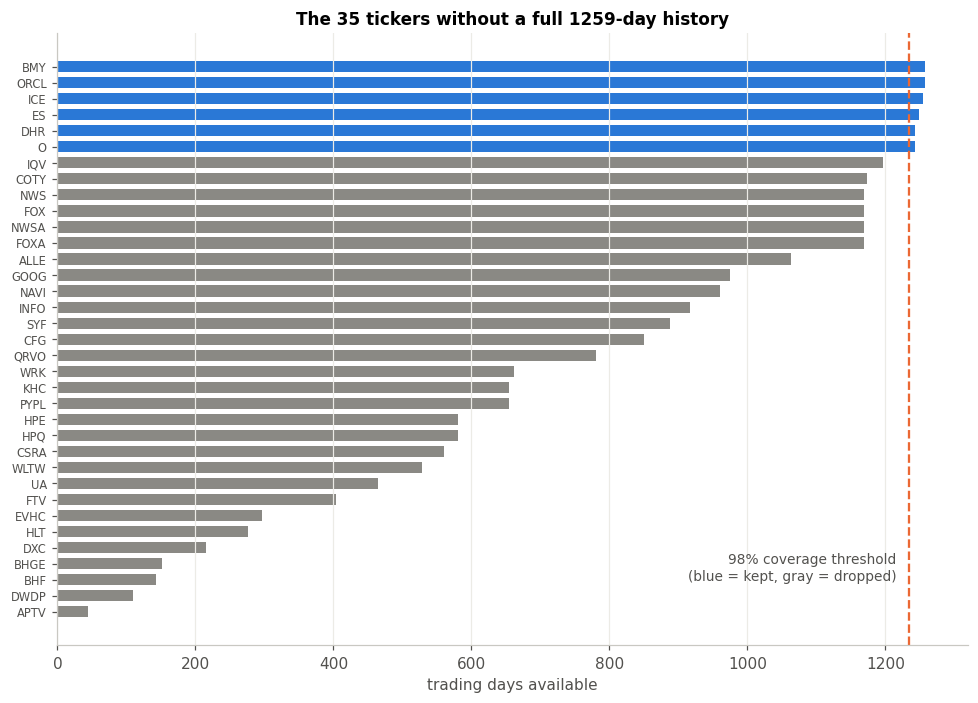

In [4]:
history = raw.groupby("Name").size()
full = history.max()
print(f"Tickers with the full {full}-day history: {(history == full).sum()} of {len(history)}")
print("Shortest histories:", history.nsmallest(8).to_dict())

short = history[history < full].sort_values()
fig, ax = plt.subplots(figsize=(9, 6.5))
keep = short >= MIN_COVERAGE * full
ax.barh(short.index, short.values, color=np.where(keep, C["blue"], C["gray"]), height=0.7)
ax.axvline(MIN_COVERAGE * full, color=C["orange"], ls="--", lw=1.5)
ax.annotate(f"{MIN_COVERAGE:.0%} coverage threshold\n(blue = kept, gray = dropped)", (MIN_COVERAGE * full, 2),
            xytext=(-8, 0), textcoords="offset points", ha="right", fontsize=9, color=C["ink2"])
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
ax.set(title=f"The {len(short)} tickers without a full {full}-day history", xlabel="trading days available")
plt.tight_layout(); plt.show()

In [5]:
close_raw = raw.pivot(index="date", columns="Name", values="close")
moves = close_raw.pct_change(fill_method=None).stack()
extreme = moves[moves.abs() > 0.35].sort_values().rename("one-day return").to_frame()
extreme.style.format("{:+.1%}")

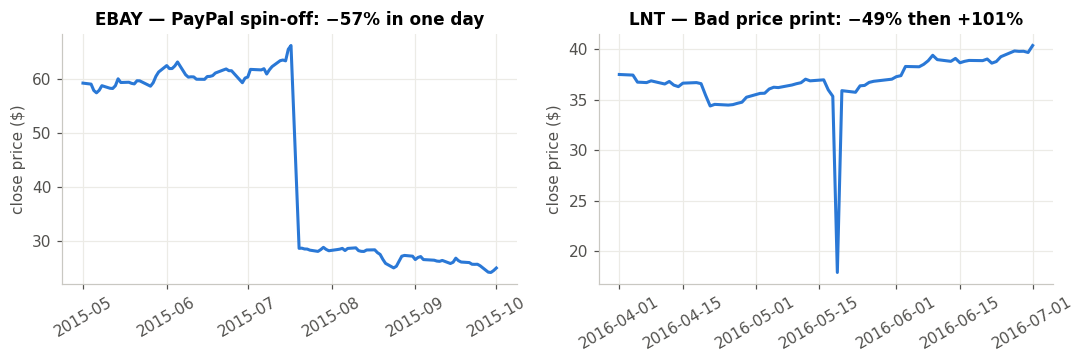

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (tkr, start, end, note) in zip(axes, [
        ("EBAY", "2015-05-01", "2015-10-01", "PayPal spin-off: −57% in one day"),
        ("LNT",  "2016-04-01", "2016-07-01", "Bad price print: −49% then +101%")]):
    s = close_raw.loc[start:end, tkr]
    ax.plot(s.index, s.values, color=C["blue"])
    ax.set(title=f"{tkr} — {note}", ylabel="close price ($)")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [7]:
# 1.3.1  Closing-price table: rows = trading days, columns = tickers
prices = raw.pivot(index="date", columns="Name", values="close").sort_index()
n_start = prices.shape[1]

# 1.3.2  Coverage filter, then forward-fill remaining short gaps
coverage = prices.notna().mean()
low_cov  = coverage[coverage < MIN_COVERAGE].index
gappy    = coverage[(coverage >= MIN_COVERAGE) & (coverage < 1)].index
prices   = prices.drop(columns=low_cov).ffill()

# 1.3.3  Remove tickers with unadjusted corporate actions
daily_simple = prices.pct_change()
artefacts    = daily_simple.columns[(daily_simple < CRASH_LIMIT).any()]
prices       = prices.drop(columns=artefacts)

# 1.3.4  Daily log returns
log_ret = np.log(prices / prices.shift(1)).iloc[1:]
assert not log_ret.isna().any().any(), "returns table must be complete"

pd.DataFrame({
    "tickers": [n_start, n_start - len(low_cov), prices.shape[1], log_ret.shape[1]],
    "detail": [
        "raw",
        f"dropped {len(low_cov)} with < {MIN_COVERAGE:.0%} coverage; forward-filled {len(gappy)}: {', '.join(gappy)}",
        f"dropped {len(artefacts)} corporate-action artefacts: {', '.join(artefacts)}",
        f"{log_ret.shape[0]} days of log returns, 0 missing values",
    ]}, index=["1.3.1 pivot", "1.3.2 coverage", "1.3.3 artefacts", "1.3.4 log returns"])

,tickers,detail
1.3.1 pivot,505,raw
1.3.2 coverage,476,dropped 29 with < 98% coverage; forward-filled...
1.3.3 artefacts,470,"dropped 6 corporate-action artefacts: BAX, DIS..."
1.3.4 log returns,470,"1258 days of log returns, 0 missing values"


In [8]:
# 1.3.5  Time-ordered split
train_ret = log_ret.iloc[:-TEST_DAYS]
test_ret  = log_ret.iloc[-TEST_DAYS:]
print(f"In-sample (estimate μ, Σ):  {train_ret.index[0].date()} → {train_ret.index[-1].date()}  ({len(train_ret)} days)")
print(f"Out-of-sample (validate):  {test_ret.index[0].date()} → {test_ret.index[-1].date()}  ({len(test_ret)} days)")

# 1.3.6  Annualised model parameters
tickers = train_ret.columns.to_numpy()
mu      = train_ret.mean().to_numpy() * TRADING_DAYS     # expected annual return of each stock
Sigma   = train_ret.cov().to_numpy()  * TRADING_DAYS     # annual covariance matrix
N       = len(mu)
vol     = np.sqrt(np.diag(Sigma))                        # each stock's own annual volatility

In-sample (estimate μ, Σ):  2013-02-11 → 2017-02-07  (1006 days)
Out-of-sample (validate):  2017-02-08 → 2018-02-07  (252 days)


## 1.4 Sanity checks on the model inputs

- $\Sigma$ is a valid covariance matrix: symmetric and positive semi-definite, so every portfolio variance $x^\top\Sigma x \ge 0$
- The values are financially plausible
- The problem is too large for exhaustive search at each *k* we plan to use

In [9]:
eig_min = np.linalg.eigvalsh(Sigma).min()
print(f"N = {N} stocks")
print(f"Σ symmetric: {np.allclose(Sigma, Sigma.T)}  |  smallest eigenvalue: {eig_min:.2e}  →  PSD: {eig_min > -1e-10}")

pd.DataFrame({
    "annual return μ":    pd.Series(mu).describe(percentiles=[.1, .5, .9]),
    "annual volatility σ": pd.Series(vol).describe(percentiles=[.1, .5, .9]),
}).loc[["min", "10%", "50%", "90%", "max"]].style.format("{:.1%}")

N = 470 stocks
Σ symmetric: True  |  smallest eigenvalue: 1.11e-03  →  PSD: True


,annual return μ,annual volatility σ
min,-29.7%,14.0%
10%,-1.7%,17.1%
50%,10.9%,23.2%
90%,23.2%,33.5%
max,56.7%,69.4%


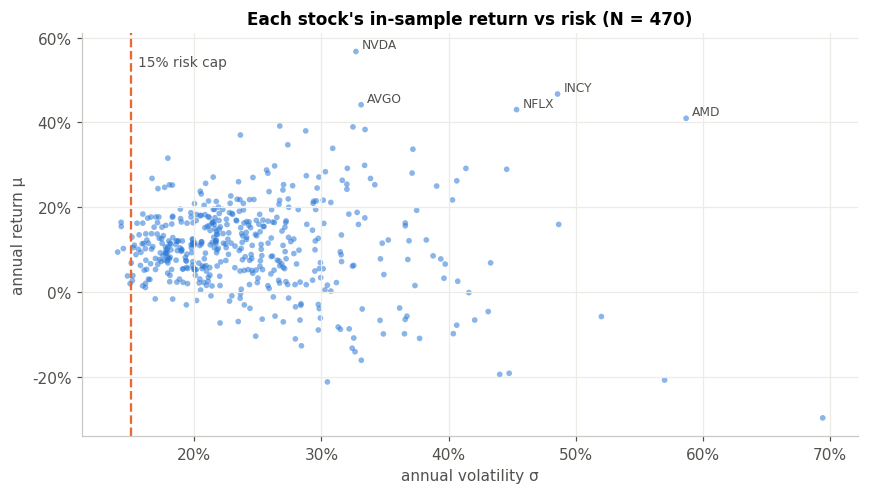

Stocks that individually satisfy the 15% cap: 6 of 470


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(vol, mu, s=14, color=C["blue"], alpha=0.55, edgecolor="none")
ax.axvline(0.15, color=C["orange"], ls="--", lw=1.5)
ax.annotate("15% risk cap", (0.15, mu.max()), xytext=(5, -2), textcoords="offset points",
            fontsize=9, color=C["ink2"], va="top")
for i in np.argsort(mu)[-5:]:
    ax.annotate(tickers[i], (vol[i], mu[i]), xytext=(4, 2), textcoords="offset points", fontsize=8, color=C["ink2"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title=f"Each stock's in-sample return vs risk (N = {N})", xlabel="annual volatility σ", ylabel="annual return μ")
plt.tight_layout(); plt.show()
print(f"Stocks that individually satisfy the 15% cap: {(vol <= 0.15).sum()} of {N}")

In [11]:
print("Search space size C(N, k) for the planned k values:")
for k in (5, 10, 20):
    print(f"  k = {k:>2}:  {comb(N, k):.2e} possible portfolios")

Search space size C(N, k) for the planned k values:
  k =  5:  1.87e+11 possible portfolios
  k = 10:  1.32e+20 possible portfolios
  k = 20:  7.55e+34 possible portfolios


In [12]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
log_ret.to_csv(PROCESSED_DIR / "log_returns_clean.csv")
print("Saved", PROCESSED_DIR / "log_returns_clean.csv", log_ret.shape)

Saved ../data/processed/log_returns_clean.csv (1258, 470)
